In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emcee
import corner

from scipy.optimize import minimize
from scipy.interpolate import UnivariateSpline

from sklearn.utils import resample

import astropy.units as u

import time
import tqdm as tqdm
from multiprocessing import Pool
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(123)

[ 0.00142689 -0.04548921  0.36606062  1.        ]


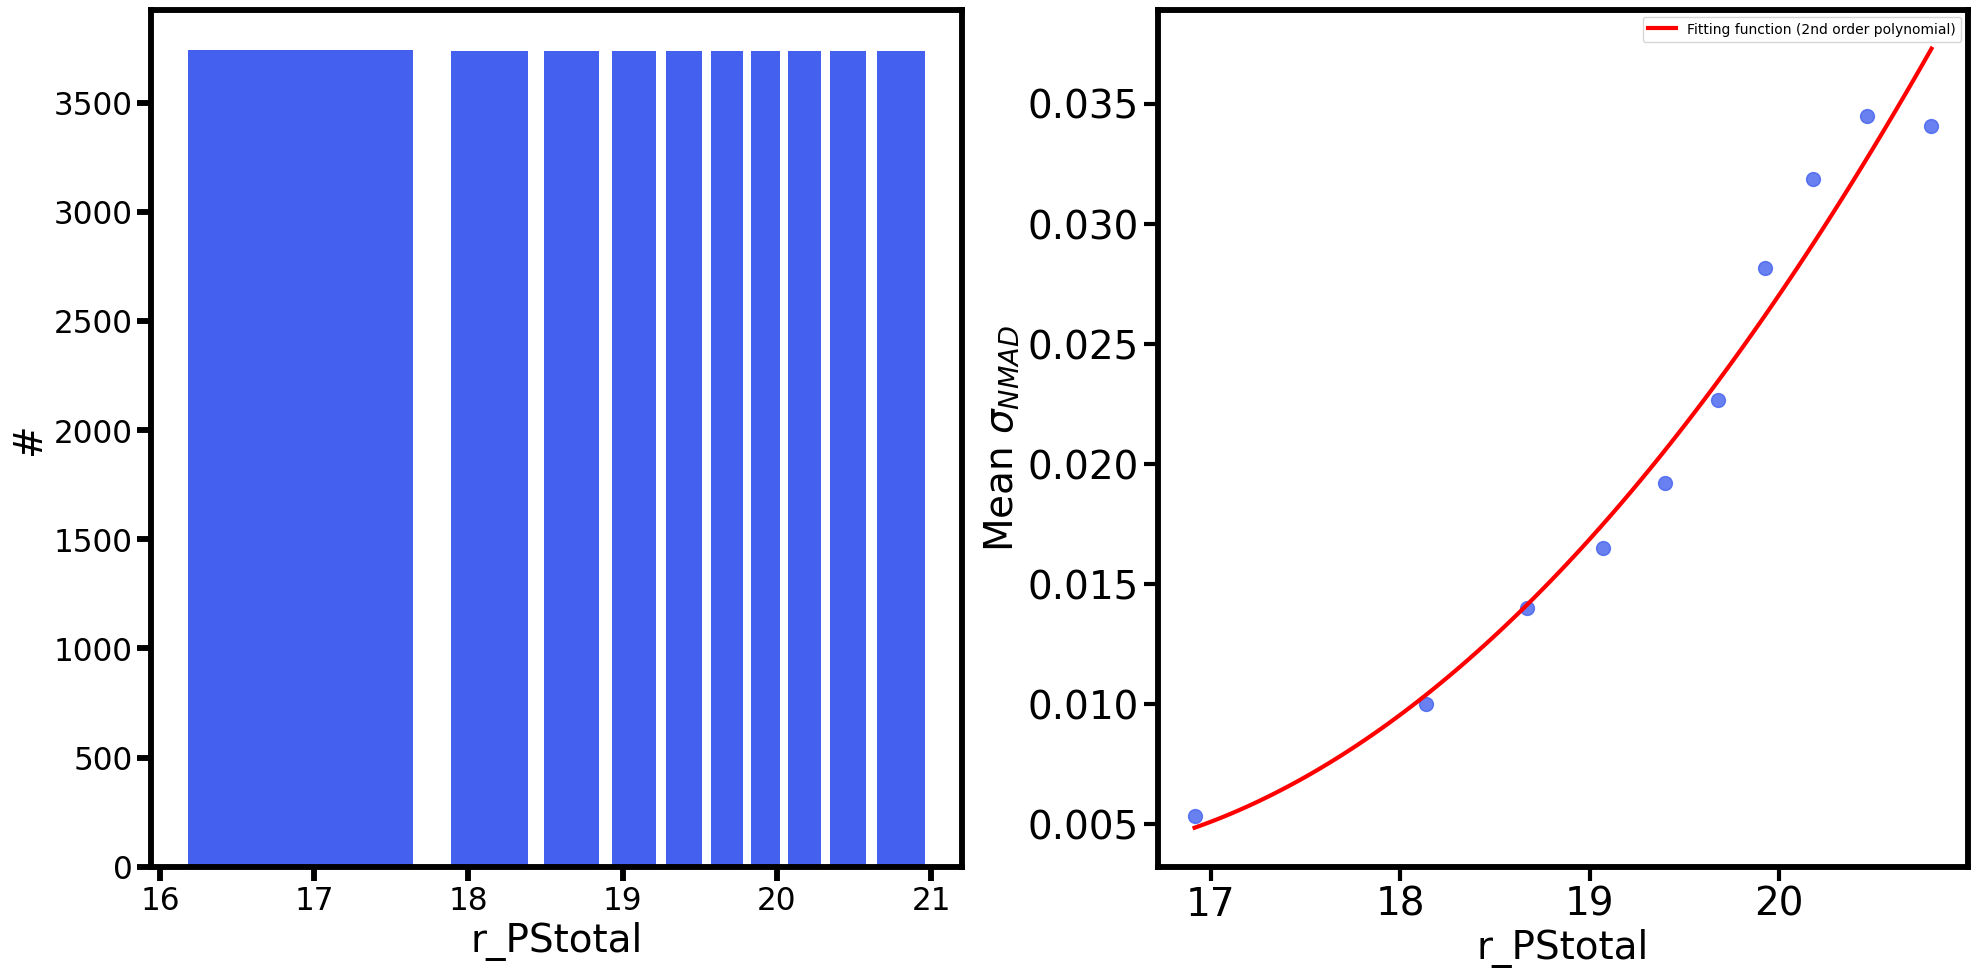

In [2]:
from galaxy_cluster_membership import *

In [3]:
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import rc, rcParams
f = 0.8

fontsize = 35 * f
labelsize = 20 * f

rc("xtick", labelsize=fontsize * f)
rc("ytick", labelsize=fontsize * f)
rcParams["axes.linewidth"] = 5.3 * f
rcParams["xtick.major.width"] = 5.3 * f
rcParams["xtick.minor.width"] = 5.3 * f
rcParams["ytick.major.width"] = 5.3 * f
rcParams["ytick.minor.width"] = 5.3 * f
rcParams["xtick.major.size"] = 12.5 * f
rcParams["xtick.minor.size"] = 6.5 * f
rcParams["ytick.major.size"] = 12.5 * f
rcParams["ytick.minor.size"] = 6.5 * f

font = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 50 * f,
        }


cm1 = plt.cm.get_cmap('jet')
cm2 = plt.cm.get_cmap('rainbow')
cm3 = plt.cm.get_cmap('gnuplot2')
cm4 = plt.cm.get_cmap('Pastel2')
cm5 = plt.cm.get_cmap('Set3')
cm6 = plt.cm.get_cmap('gist_rainbow')

color_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
colors1 = [cm1(value) for value in color_values]
colors2 = [cm2(value) for value in color_values]
colors3 = [cm3(value) for value in color_values]
colors4 = [cm4(value) for value in color_values]
colors5 = [cm5(value) for value in color_values]
colors6 = [cm6(value) for value in color_values]

### Define functions

In [ ]:
def SIS_density(R, params):
    '''
    SIS profile with an exponential cutoff plus a constant field density
    '''

    Sigma0, alpha, Rt, tau, Sigma_field = params

    Sigma_c = Sigma0 * R**(-alpha) * np.exp(-(R/Rt)**tau)

    Sigma_dens = Sigma_c + Sigma_field

    return Sigma_dens



def SIS_density_cumulative(R, dR, params):
    '''
    SIS cumulative profile with an exponential cutoff plus a constant field density
    '''

    Sigma0, alpha, Rt, tau, Sigma_field = params

    Sigma_c = Sigma0 * R**(-alpha) * np.exp(-(R/Rt)**tau)

    cum_f = np.pi * Sigma_field * R**2
    #Polar integral of Sigma_c to obtain the cumulative density profile
    cum_c = 2*np.pi*np.array([np.sum(Sigma_c[R < R[i]] * R[R < R[i]] * dR) for i in range(len(R))])
    cum_dens = cum_f + cum_c

    return cum_dens


def splashback_radius(R, r200_deg, best_params, model_density):
    '''
    Compute the 2D splashback radius (Rsp)
    The 3D r_sp can be obtained by r_sp = sqrt(pi/2) * Rsp (More et al. 2016, see also Lucas's paper (Gabriel-Silva & Sodré 2025))
    '''

    Sigma_ = model_density(R, best_params)

    #This is like doing dlog(Sigma_)/dlog(R) = R/Sigma_ * dSigma_/dR
    #s is for smoothing the function. The final result depends on the value of s, but for lack of further information we set s=None.
    Sigma_spline = UnivariateSpline(R, Sigma_, s=None)
    gamma = R/Sigma_ * Sigma_spline.derivative()(R)

    #I am limiting the search for the minimum of gamma to R < 4*r200, 
    #because after that the profile is dominated by the background and it creates a false minimum in gamma
    Rsp = R[np.argmin(gamma[R/r200_deg < 4])]

    return Rsp, gamma


def ellipticity(clust_dist, Rsp, ras, decs, ra0, dec0, cartesian=False):
    '''
    Compute cluster's ellipticity; see Shin et al. (2018) for reference. 
    '''

    select_aperture = clust_dist < Rsp

    #RA and Dec needs to be centered on the origin for the ellipticity calculation to make sense
    xi = ras[select_aperture] - ra0
    yi = decs[select_aperture] - dec0

    if cartesian:
        #The difference between using cartesian or spherical coordinates for the 
        #ellipticity calculation is small (difference in 3rd decimal place) for small angles (clusters' angular sizes are small)
        x_cartesian = np.cos(np.deg2rad(ras[select_aperture])) * np.cos(np.deg2rad(decs[select_aperture]))
        y_cartesian = np.cos(np.deg2rad(ras[select_aperture])) * np.sin(np.deg2rad(decs[select_aperture]))
        z_cartesian = np.sin(np.deg2rad(decs[select_aperture]))

        xi = x_cartesian - np.mean(x_cartesian)
        yi = z_cartesian - np.mean(z_cartesian)

    wi = 1 / (xi**2 + yi**2)
    Ixx = np.sum(xi**2 * wi) / np.sum(wi)
    Iyy = np.sum(yi**2 * wi) / np.sum(wi)
    Ixy = np.sum(xi * yi * wi) / np.sum(wi)

    e1 = (Ixx - Iyy) / (Ixx + Iyy)
    e2 = (2 * Ixy) / (Ixx + Iyy)
    e = np.sqrt(e1**2 + e2**2)

    return e


In [ ]:
def log_likelihood(params, R, dR, data): 
    
    model_density = SIS_density_cumulative(R, dR, params)
    residuals = data - model_density
    sigma = np.sqrt(1/len(data) * (residuals)**2)
    
    # Assuming Gaussian noise, the log likelihood is proportional to the square of residuals
    return -0.5 * np.sum(residuals**2/sigma**2 + np.log(2 * np.pi * sigma**2)) * 0.2


# Define prior distributions (simple uniform priors in this case)
def log_prior(params, r200_deg):
    Sigma0, alpha, Rt, tau, Sigma_field = params
    
    if 0 < Sigma0 < 100 and 0 < alpha < 20 and 0 < Sigma_field < 100 and 0 < Rt < 10*r200_deg and 0 < tau < 10:
        return 0.0  # log(1) = 0, uniform prior
    return -np.inf  # log(0) = -inf, to reject parameters outside these ranges
    

def log_probability(params, R, dR, data, r200_deg):
    lp = log_prior(params, r200_deg)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params, R, dR, data)


def run_mcmc(nsteps, nwalkers, guess, log_probability, args, moves, multi_process=False):
    '''
    Wrapper for running the MCMC with emcee, with or without multiprocessing.

    Parameters
    ----------
    nsteps : int
        Number of MCMC steps to run.
    guess : array-like
        Initial guess for the parameters.
    log_probability : function
        Function to compute the log-probability.
    args : tuple
        Additional arguments to pass to the log-probability function.
    moves : emcee.moves object
        Move strategy for the MCMC sampler.
    multi_process : bool, optional
        Whether to use multiprocessing. Default is False.
    '''

    pos = guess + 1e-4 * np.random.randn(nwalkers, len(guess))
    _, ndim = pos.shape

    if multi_process == False:
        sampler = emcee.EnsembleSampler(
            nwalkers, 
            ndim, 
            log_probability, 
            args=args,
            moves=moves
        )
        sampler.run_mcmc(pos, nsteps, progress=True);

    elif multi_process == True:
        with Pool(processes=nwalkers) as pool:
            sampler = emcee.EnsembleSampler(
                nwalkers,
                ndim,
                log_probability,
                args=args,
                pool=pool
                )
            
            start = time.time()

            sampler.run_mcmc(pos, nsteps, progress=True)
            
            end = time.time()
            multi_time = end - start
            print("Multiprocessing took {0:.1f} seconds".format(multi_time))

    return sampler

In [ ]:
def chi_squared(params, R, dR, observed_density):
    modeled_density = SIS_density_cumulative(R, dR, params)
    return np.sum((observed_density - modeled_density)**2)


def fit_cumulative(R, dR, data, init, r200_deg):
    
    bounds = [
        (0, 100), #Sigma0
        (0, 20), #alpha
        (0, 10*r200_deg), #Rt
        (0, 10), #tau
        (0, 20) #Sigma_field
    ]

    fit = minimize(chi_squared, init, args=(R, dR, data), method='Nelder-Mead', bounds=bounds)
    return fit


def bootstrap_fit(data, init, r200_deg, x0, y0, B=1000):
    estimates = np.zeros((B, 8))  # 5 model parameters + chi2 + Rsp + ellipticity

    bounds = [
        (0, 100), #Sigma0
        (0, 20), #alpha
        (0, 10*r200_deg), #Rt
        (0, 10), #tau   
        (0, 20) #Sigma_field
    ]

    for b in tqdm.tqdm(range(B)):
        resampled_data = resample(data)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        #I am letting the cluster's center (x0, y0) fixed
        Rp = clustercentric_distance(x, y, x0, y0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        # try:
        fit_b = minimize(chi_squared, init, args=(R, dR, Fz), method='Nelder-Mead', bounds=bounds)

        Rsp = splashback_radius(R, dR, fit_b.x, SIS_density_cumulative)
        e = ellipticity(Rp, Rsp, x, y, x0, y0)


        # if fit_b.success:
        estimates[b, 0] = fit_b.x[0]  # Sigma0
        estimates[b, 1] = fit_b.x[1]  # alpha
        estimates[b, 2] = fit_b.x[2]  # Rt
        estimates[b, 3] = fit_b.x[3]  # tau
        estimates[b, 4] = fit_b.x[4]  # Sigma_field
        estimates[b, 5] = chi_squared(fit_b.x, R, dR, Fz)  # chi2
        estimates[b, 6] = Rsp  # Rsp
        estimates[b, 7] = e    # ellipticity
        # except:
        #     continue
    
    return pd.DataFrame(estimates, columns=["Sigma0", "alpha", "Rt", "tau", "Sigma_field", "chi2", "Rsp", "e"])

### Guessing parameters

In [23]:
i_mock = 1

t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
members = t["phot_member"] == 1
ras = np.array(t["RA"][members]) #deg
decs = np.array(t["DEC"][members]) #deg
zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
zs = np.array(t["z_app"][members]) 


x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


side = min(max(ras) - min(ras), max(decs) - min(decs))
all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

In [24]:
#Distribuição cumulativa observada
Rp = clustercentric_distance(ras, decs, x0, y0)
Hz, Rcz = np.histogram(Rp, bins=100, density=True)
dR = Rcz[1] - Rcz[0]
Fz = np.cumsum(Hz)*dR
R = Rcz[1:]

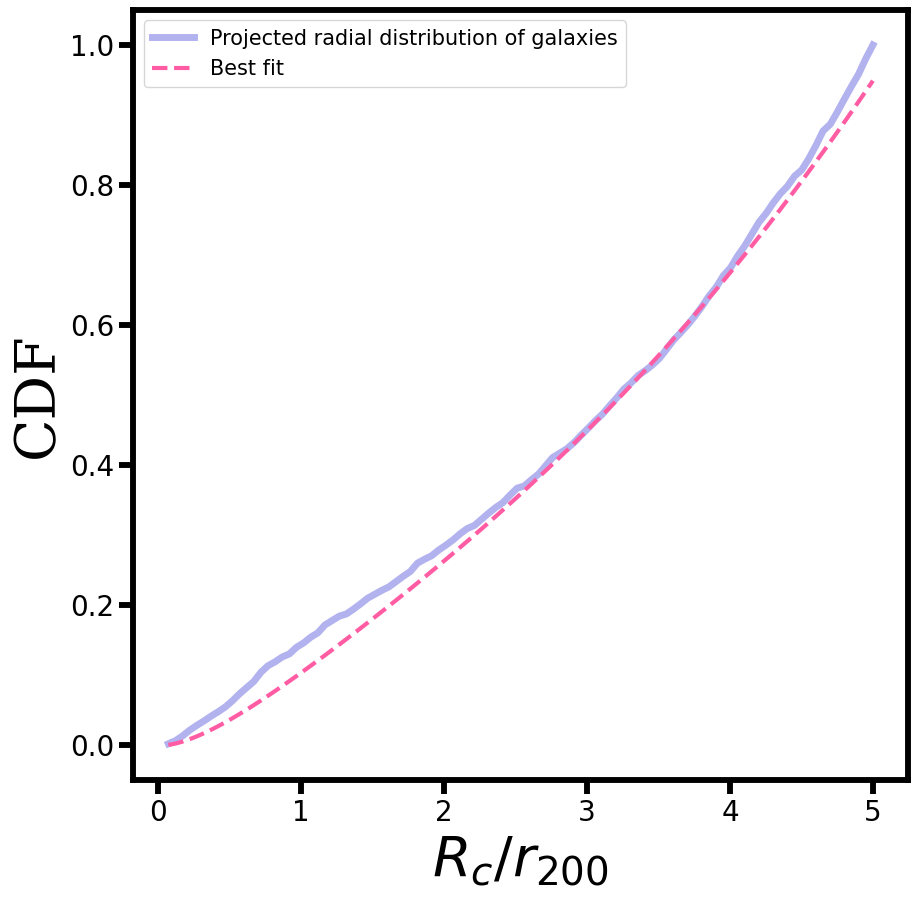

In [10]:
cum_dens = SIS_density_cumulative(R, dR, [1.1, 0.3, 1*r200_deg, 1, 0.5])

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

### Run for all clusters (mock)

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

first_guess = np.array([1.1, 0.3, 1*r200_deg, 1, 0.5]) #initial guess for [Sigma0, alpha, Rt, tau, Sigma_field], same for all clusters
labels = [r"$\Sigma_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]

i_mock_list = []
Sigma0_list = []
alpha_list = []
Rt_list = []
tau_list = []
Sigma_field_list = []
Rsp_list = []
e_list = []   


for i_mock in np.arange(50):

    print("COMPUTING FOR MOCK CLUSTER", i_mock)

    t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
    members = t["phot_member"] == 1
    ras = np.array(t["RA"][members]) #deg
    decs = np.array(t["DEC"][members]) #deg
    zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
    zs = np.array(t["z_app"][members]) 


    x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
    y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
    r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
    r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
    m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
    z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


    side = min(max(ras) - min(ras), max(decs) - min(decs))
    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    
    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, x0, y0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    #======================================
    #GUESSING PARAMETERS WITH MCMC
    #======================================

    sampler = run_mcmc(nsteps, 
                       nwalkers,
                       first_guess,
                       log_probability, 
                        args=(R, dR, Fz, r200_deg), 
                        moves=emcee.moves.StretchMove(),
                        multi_process=False)

    samples = sampler.get_chain()

    #flat = flatten the chains across the ensample
    #discard = discard the burn_in phase
    #thin = "thins" the sample every N iterations (for instance 15)
    flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
    means = np.mean(flat_samples, axis=0)


    fig, axes = plt.subplots(6, figsize=(10, 15), sharex=True)
    # Styling
    rcParams["font.size"] = 10
    rcParams["axes.labelsize"] = 10
    rcParams["xtick.labelsize"] = 10
    rcParams["ytick.labelsize"] = 10

    for i in range(len(first_guess)):
        ax = axes[i]
        ax.plot(samples[:, :, i], "blue", alpha=0.3)
        ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
        ax.set_xlim(0, len(samples))
        ax.set_ylabel(labels[i], fontdict=font)
        ax.yaxis.set_label_coords(-0.1, 0.5)

        print(np.median(samples[int(burn_in*nsteps):, :, i]))

    axes[-1].set_xlabel("step number", fontdict=font);

    #Guess after running the mcmc (median of parameters with 20% burn-in)
    second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 5)])

    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/SIS/trace_plot_mcmc_mock{}.png".format(i_mock),
                                         dpi='figure', format='png')

    #======================================
    #MINIMIZING CHI2 TO FIND BEST FIT
    #======================================
    fit = fit_cumulative(R, dR, Fz, second_guess, r200_deg)
    Rsp = splashback_radius(R, dR, fit.x, SIS_density)
    e = ellipticity(Rp, Rsp, ras, decs, x0, y0)

    cum_dens = SIS_density(R, dR, fit.x)

    # Run bootstrap
    t0 = time.time()
    nboot = 1000
    boot_results = bootstrap_fit(all_galaxies, fit.x, r200_deg, x0, y0, B=nboot)
    print("Bootstrap time taken:", time.time() - t0)
    boot_results.to_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/boot_results_mock{}.csv".format(i_mock), index=False)


    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/boot_results_outliers_removed_mock{}.csv".format(i_mock), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/SIS/boostrap_parameter_distribution_mock{}.png".format(i_mock), dpi='figure', format='png')


    # Plot cumulative density fit and bootstrap results
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)   
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel("CDF", fontdict=font)

    for _, row in boot_results_outliers_removed.iterrows():
        params = row[:5].values
        cum_model = SIS_density(R, dR, params)
        ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

    ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
    ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

    ax.legend(fontsize=15)
    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/SIS/cumulative_density_fit_mock{}.png".format(i_mock), dpi='figure', format='png')


    #SAVING BEST FIT PARAMETERS
    i_mock_list.append(i_mock)
    Sigma0_list.append(fit.x[0])
    alpha_list.append(fit.x[1])
    Rt_list.append(fit.x[2]) #deg
    tau_list.append(fit.x[3])
    Sigma_field_list.append(fit.x[4]) 
    Rsp_list.append(Rsp) #deg
    e_list.append(e)
    
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/i_mock_list", i_mock_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Sigma0_list", Sigma0_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/alpha_list", alpha_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Rt_list", Rt_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/tau_list", tau_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Sigma_field_list", Sigma_field_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Rsp_list", Rsp_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/e_list", e_list)

### Run for SCALE clusters

In [7]:
cl_names = ["A133", "A463", "A957", "A970", "A978", "A993", "A1069", "A1631", "A1644", "A2415", "A2734", "A3104", "A3112", 
            "A3122", "A3809", "MCXCJ0340-4542", "WHLJ012023-000444", "[YMV2007]514", "[YMV2007]841", "[YMV2007]1540"]

In [ ]:
cl_name = "A133"

t_members = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
members = t_members["flag_member_photz1"] == 0
ras = t_members["ra"][members].values
decs = t_members["dec"][members].values

all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
ra0 = clusters_properties["R.A."][clusters_properties["Cluster"] == cl_name].values[0]
dec0 = clusters_properties["Dec."][clusters_properties["Cluster"] == cl_name].values[0]
r200_mpc = clusters_properties["R200"][clusters_properties["Cluster"] == cl_name].values[0]
z_cluster = clusters_properties["z"][clusters_properties["Cluster"] == cl_name].values[0]

kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

In [12]:
#Distribuição cumulativa observada
Rp = clustercentric_distance(ras, decs, ra0, dec0)
Hz, Rcz = np.histogram(Rp, bins=100, density=True)
dR = Rcz[1] - Rcz[0]
Fz = np.cumsum(Hz)*dR
R = Rcz[1:]

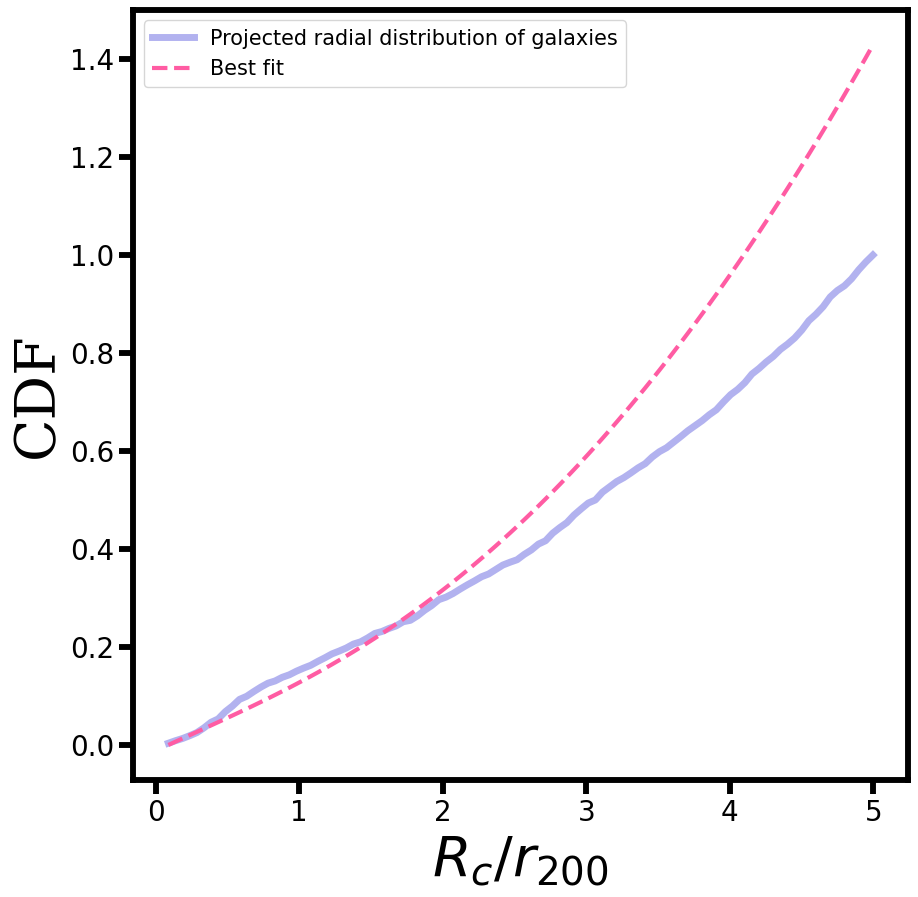

In [16]:
cum_dens = SIS_density(R, dR, [0.05, 1.0, 1*r200_deg, 1, 0.09])

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

first_guess = np.array([0.05, 0.1, 1*r200_deg, 1, 0.09]) #initial guess for [Sigma0, alpha, Rt, tau, Sigma_field]

sampler = run_mcmc(nsteps, 
                    nwalkers,
                    first_guess,
                    log_probability, 
                    args=(R, dR, Fz, r200_deg), 
                    moves=emcee.moves.StretchMove(),
                    multi_process=False)

samples = sampler.get_chain()

#flat = flatten the chains across the ensample
#discard = discard the burn_in phase
#thin = "thins" the sample every N iterations (for instance 15)
flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
means = np.mean(flat_samples, axis=0)

0.21125363387179766
0.7937658087110573
0.1473659849194371
0.6135074500643228
0.10275315699899773


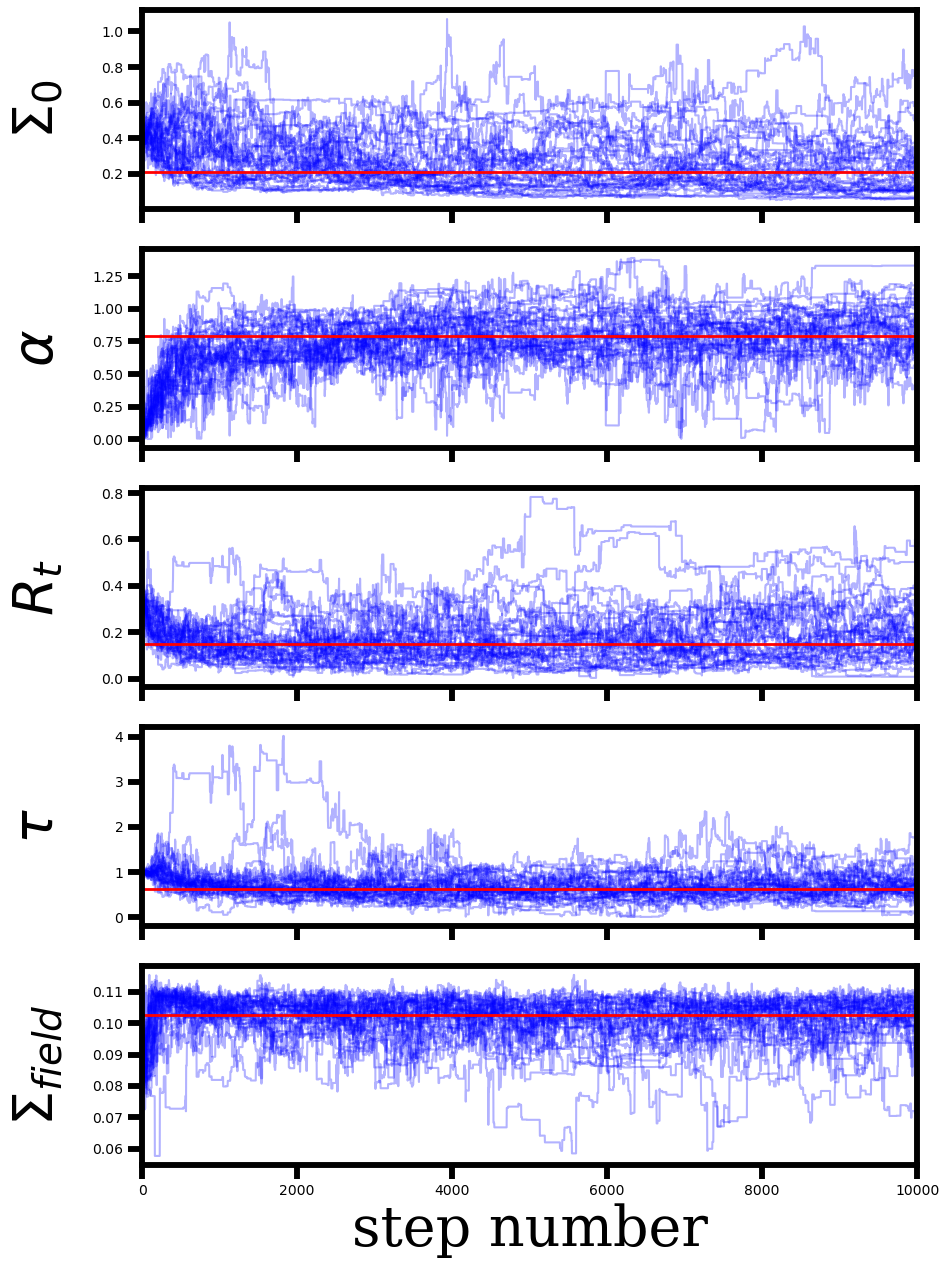

In [ ]:
labels = [r"$\Sigma_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]

fig, axes = plt.subplots(5, figsize=(10, 15), sharex=True)
# Styling
rcParams["font.size"] = 10
rcParams["axes.labelsize"] = 10
rcParams["xtick.labelsize"] = 10
rcParams["ytick.labelsize"] = 10

for i in range(len(first_guess)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "blue", alpha=0.3)
    ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontdict=font)
    ax.yaxis.set_label_coords(-0.1, 0.5)

    # print(np.median(samples[int(burn_in*nsteps):, :, i]))

axes[-1].set_xlabel("step number", fontdict=font);

#Guess after running the mcmc (median of parameters with 20% burn-in)
second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 5)])

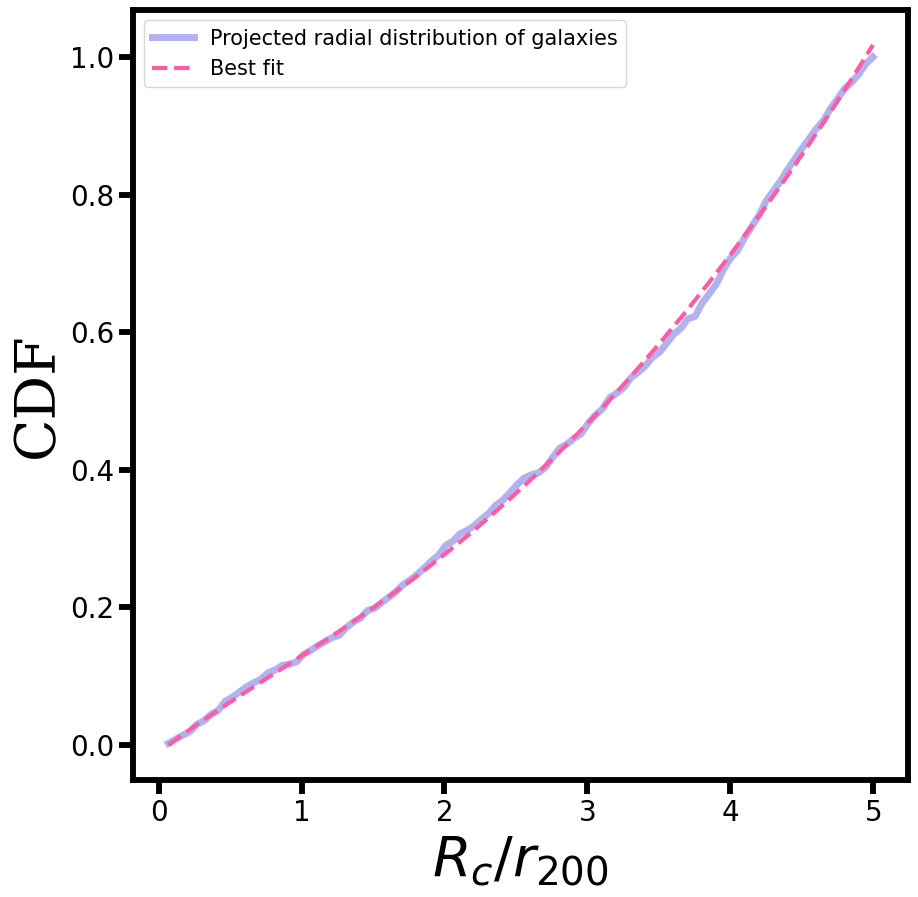

In [49]:
cum_dens = SIS_density(R, dR, second_guess)

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [54]:
fit = fit_cumulative(R, dR, Fz, second_guess, r200_deg)
Rsp = splashback_radius(R, dR, fit.x, SIS_density)
e = ellipticity(Rp, Rsp, ras, decs, ra0, dec0)

cum_dens = SIS_density(R, dR, fit.x)

# Run bootstrap
t0 = time.time()
nboot = 1000
boot_results = bootstrap_fit(all_galaxies, fit.x, r200_deg, ra0, dec0, B=nboot)
print("Bootstrap time taken:", time.time() - t0)

100%|██████████| 1000/1000 [23:47<00:00,  1.43s/it]

Bootstrap time taken: 1427.551293849945


In [ ]:
# Remove outliers
z = boot_results
for col in boot_results.columns:
    Q1 = boot_results[col].quantile(0.25)
    Q3 = boot_results[col].quantile(0.75)
    IQR = Q3 - Q1
    z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
    print("Remaining samples after outlier removal:", len(z))
boot_results_outliers_removed = z

Remaining samples after outlier removal: 926
Remaining samples after outlier removal: 921
Remaining samples after outlier removal: 914
Remaining samples after outlier removal: 862
Remaining samples after outlier removal: 785
Remaining samples after outlier removal: 765
Remaining samples after outlier removal: 765
Remaining samples after outlier removal: 758


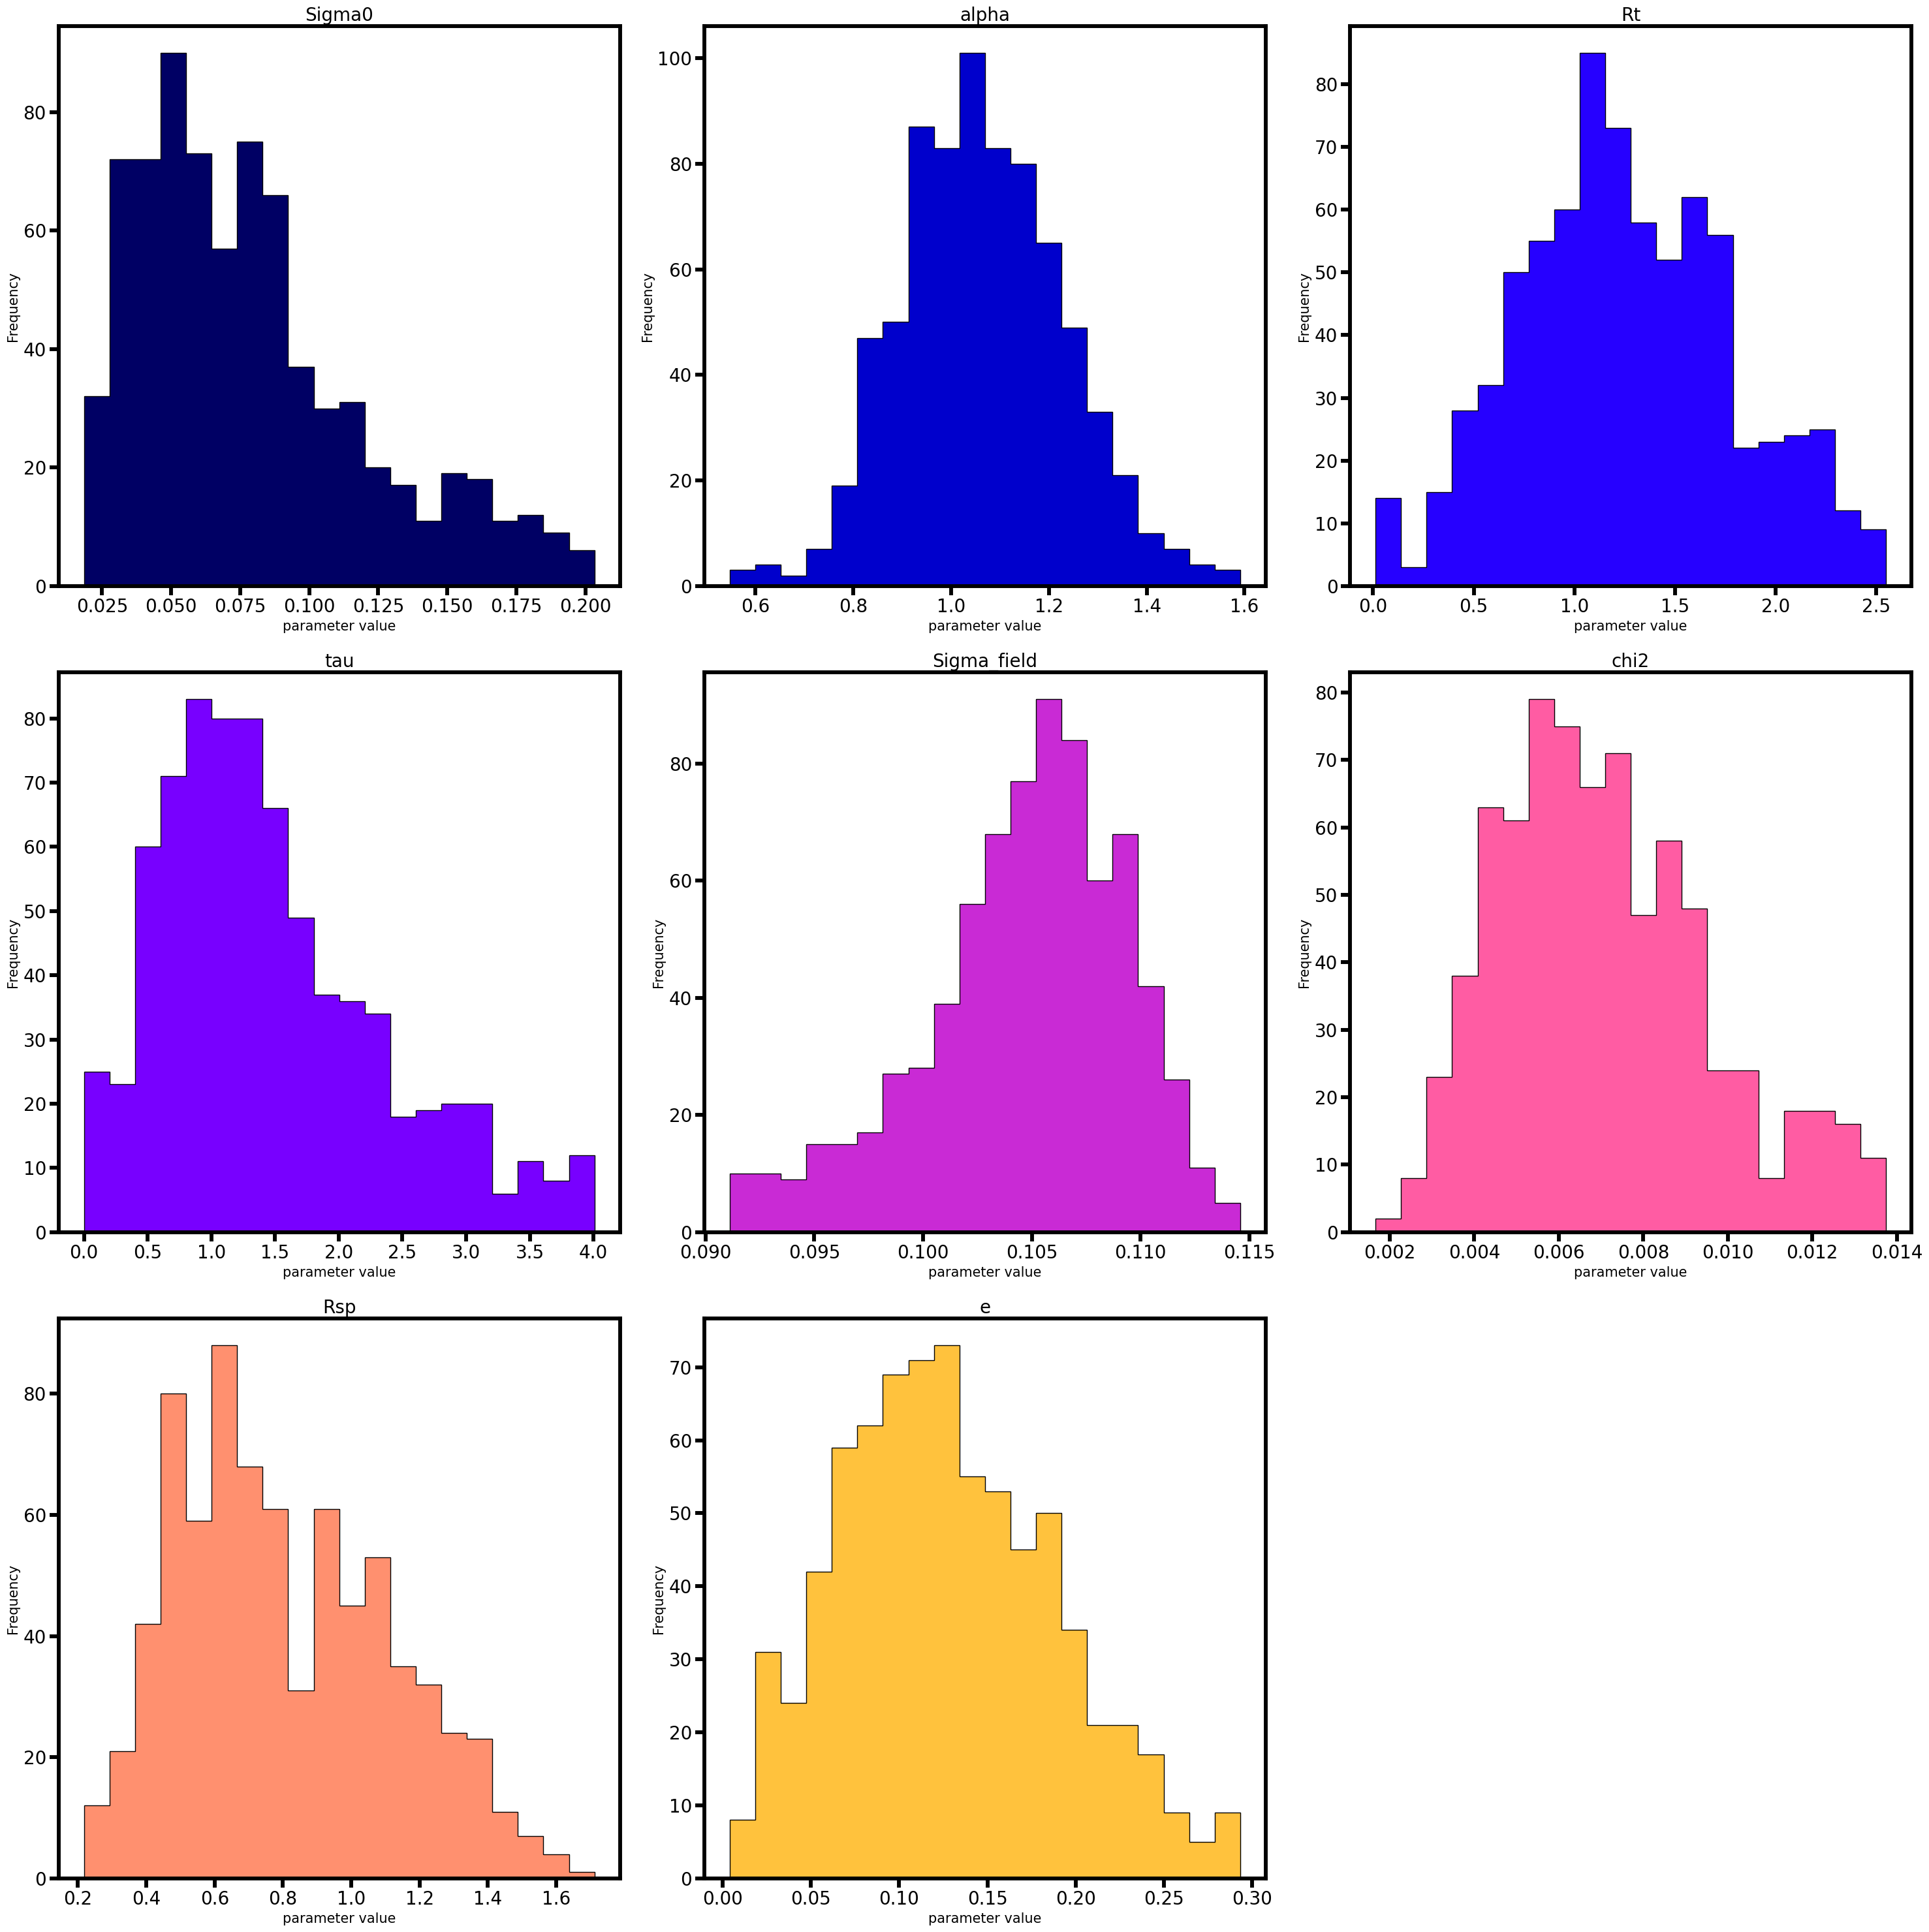

In [57]:
# Plot parameter distributions
rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
plt.figure(figsize=(30, 30))
for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
    plt.subplot(3, 3, i+1)
    if (col == "R0") | (col == "Rt") | (col == "Rsp"):
        plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
    else:
        plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
    plt.title(col, fontsize=20) 
    plt.xlabel("parameter value", fontsize=15)
    plt.ylabel("Frequency", fontsize=15)
plt.tight_layout()

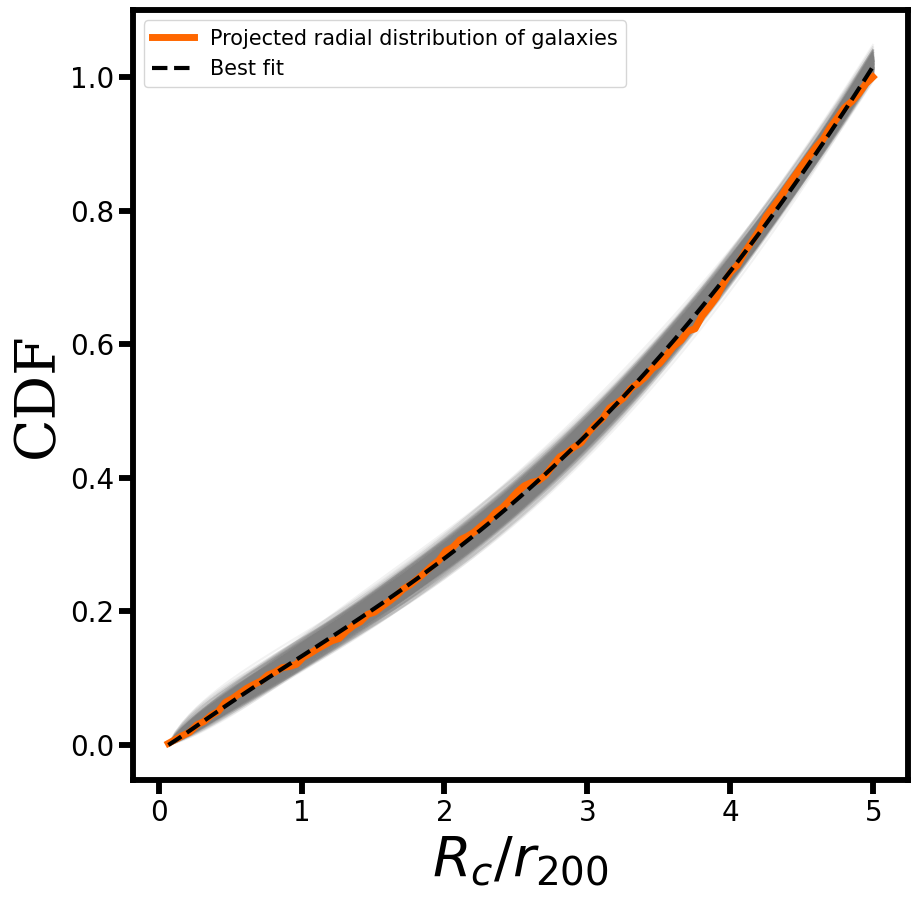

In [58]:
# Plot cumulative density fit and bootstrap results
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)

for _, row in boot_results_outliers_removed.iterrows():
    params = row[:5].values
    cum_model = SIS_density(R, dR, params)
    ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

ax.legend(fontsize=15)

#### Loop

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

labels = [r"$\Sigma_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]

cl_name_list = []
Sigma0_list = []
alpha_list = []
Rt_list = []
tau_list = []
Sigma_field_list = []
Rsp_list = []
e_list = []  


for cl_name in cl_names:

    print("COMPUTING FOR CLUSTER", cl_name)

    t_members = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
    members = t_members["flag_member_photz1"] == 0
    ras = t_members["ra"][members].values
    decs = t_members["dec"][members].values

    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
    ra0 = clusters_properties["R.A."][clusters_properties["Cluster"] == cl_name].values[0]
    dec0 = clusters_properties["Dec."][clusters_properties["Cluster"] == cl_name].values[0]
    r200_mpc = clusters_properties["R200"][clusters_properties["Cluster"] == cl_name].values[0]
    z_cluster = clusters_properties["z"][clusters_properties["Cluster"] == cl_name].values[0]

    kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
    r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg


    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, ra0, dec0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    #======================================
    #GUESSING PARAMETERS WITH MCMC
    #======================================

    irst_guess = np.array([0.05, 1.0, 1*r200_deg, 1, 0.09]) #initial guess for [Sigma0, alpha, Rt, tau, Sigma_field], same for all clusters

    sampler = run_mcmc(nsteps, 
                        nwalkers,
                        first_guess,
                        log_probability, 
                        args=(R, dR, Fz, r200_deg), 
                        moves=emcee.moves.StretchMove(),
                        multi_process=False)

    samples = sampler.get_chain()

    #flat = flatten the chains across the ensample
    #discard = discard the burn_in phase
    #thin = "thins" the sample every N iterations (for instance 15)
    flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
    means = np.mean(flat_samples, axis=0)

    
    fig, axes = plt.subplots(5, figsize=(10, 15), sharex=True)
    # Styling
    rcParams["font.size"] = 10
    rcParams["axes.labelsize"] = 10
    rcParams["xtick.labelsize"] = 10
    rcParams["ytick.labelsize"] = 10

    for i in range(len(first_guess)):
        ax = axes[i]
        ax.plot(samples[:, :, i], "blue", alpha=0.3)
        ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
        ax.set_xlim(0, len(samples))
        ax.set_ylabel(labels[i], fontdict=font)
        ax.yaxis.set_label_coords(-0.1, 0.5)

        # print(np.median(samples[int(burn_in*nsteps):, :, i]))

    axes[-1].set_xlabel("step number", fontdict=font);

    plt.savefig("../figures/SCALE/bootstrap_results_08022026/SIS/trace_plot_mcmc_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')

    #Guess after running the mcmc (median of parameters with 20% burn-in)
    second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 5)])

    #======================================
    #MINIMIZING CHI2 TO FIND BEST FIT
    #======================================
    fit = fit_cumulative(R, dR, Fz, second_guess, r200_deg)
    Rsp = splashback_radius(R, dR, fit.x, SIS_density)
    e = ellipticity(Rp, Rsp, ras, decs, ra0, dec0)

    cum_dens = SIS_density(R, dR, fit.x)

    # Run bootstrap
    t0 = time.time()
    nboot = 1000
    boot_results = bootstrap_fit(all_galaxies, fit.x, r200_deg, ra0, dec0, B=nboot)
    print("Bootstrap time taken:", time.time() - t0)
    boot_results.to_csv("tables/SCALE/bootstrap_results_08022026/SIS/boot_results_cluster-{}.csv".format(cl_name), index=False)


    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/SCALE/bootstrap_results_08022026/SIS/boot_results_outliers_removed_cluster-{}.csv".format(cl_name), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/SCALE/bootstrap_results_08022026/SIS/boostrap_parameter_distribution_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')


    # Plot cumulative density fit and bootstrap results
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)   
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel("CDF", fontdict=font)

    for _, row in boot_results_outliers_removed.iterrows():
        params = row[:5].values
        cum_model = SIS_density(R, dR, params)
        ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

    ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
    ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

    ax.legend(fontsize=15)
    plt.savefig("../figures/SCALE/bootstrap_results_08022026/SIS/cumulative_density_fit_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')
    

    #SAVING BEST FIT PARAMETERS
    cl_name_list.append(cl_name)
    Sigma0_list.append(fit.x[0])
    alpha_list.append(fit.x[1])
    Rt_list.append(fit.x[2]) #deg
    tau_list.append(fit.x[3])
    Sigma_field_list.append(fit.x[4]) 
    Rsp_list.append(Rsp) #deg
    e_list.append(e)
    
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/i_mock_list", cl_name_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/Sigma0_list", Sigma0_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/alpha_list", alpha_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/Rt_list", Rt_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/tau_list", tau_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/Sigma_field_list", Sigma_field_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/Rsp_list", Rsp_list)
    np.save("tables/SCALE/bootstrap_results_08022026/SIS/e_list", e_list)

### Recompute splashback radius (can delete this when it's done)

In [ ]:
nboot = 1000

Rsp_list = []
e_list = []

for i_mock in np.arange(0, 50, 1):

    print("#COMPUTING FOR MOCK CLUSTER ", i_mock)

    t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
    members = t["phot_member"] == 1
    ras = np.array(t["RA"][members]) #deg
    decs = np.array(t["DEC"][members]) #deg
    zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
    zs = np.array(t["z_app"][members]) 

    x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
    y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
    r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
    r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
    m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
    z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]

    side = min(max(ras) - min(ras), max(decs) - min(decs))
    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    Sigma0 = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Sigma0_list.npy")[i_mock]
    alpha = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/alpha_list.npy")[i_mock]
    Rt = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Rt_list.npy")[i_mock]
    tau = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/tau_list.npy")[i_mock]
    Sigma_field = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/Sigma_field_list.npy")[i_mock]

    best_params = [Sigma0, alpha, Rt, tau, Sigma_field]

    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, x0, y0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)

    Rsp, gamma = splashback_radius(R, r200_deg, best_params, SIS_density)
    e = ellipticity(Rp, Rsp, ras, decs, x0, y0)

    boot_results = pd.read_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/SIS/boot_results_mock{}.csv".format(i_mock))

    Rsp_list_boot = []
    e_list_boot = []

    for n in tqdm.tqdm(range(nboot)):

        resampled_data = resample(all_galaxies)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        #I am letting the cluster's center (x0, y0) fixed
        Rp = clustercentric_distance(x, y, x0, y0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        params = np.array([boot_results[col][n] for col in boot_results.columns[:-3]])

        Rsp_boot, gamma_boot = splashback_radius(R, r200_deg, params, SIS_density)
        ax.plot(R/r200_deg, gamma_boot, lw=1.0, c="#9d4edd", alpha=0.5)
        e_boot = ellipticity(Rp, Rsp, x, y, x0, y0)

        Rsp_list_boot.append(Rsp_boot)
        e_list_boot.append(e_boot)

    ax.plot(R/r200_deg, gamma, lw=3.0, c="#04052e")
    ax.axvline(Rsp/r200_deg, lw=3.0, color="black", label=r"$R_{sp}$")
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel(r"$\gamma(R)$", fontdict=font)
    ax.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles_mocks/bootstrap_results_19-02-2026/SIS/gamma(R)_mock{}.png".format(i_mock), dpi='figure', format='png')


    # SAVING RESULTS
    boot_results["Rsp"] = Rsp_list_boot 
    boot_results["e"] = e_list_boot
    boot_results.to_csv("tables/testing-on-mocks/bootstrap_results_19-02-2026/SIS/boot_results_mock{}.csv".format(i_mock), index=False)

    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/testing-on-mocks/bootstrap_results_19-02-2026/SIS/boot_results_outliers_removed_mock{}.csv".format(i_mock), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles_mocks/bootstrap_results_19-02-2026/SIS/boostrap_parameter_distribution_mock{}.png".format(i_mock), dpi='figure', format='png')


    Rsp_list.append(Rsp)
    e_list.append(e)

    np.save("tables/testing-on-mocks/bootstrap_results_19-02-2026/SIS/Rsp_list", Rsp_list)
    np.save("tables/testing-on-mocks/bootstrap_results_19-02-2026/SIS/e_list", e_list)
    

#COMPUTING FOR MOCK CLUSTER  0


100%|██████████| 1000/1000 [14:40<00:00,  1.14it/s]


Remaining samples after outlier removal: 979
Remaining samples after outlier removal: 979
Remaining samples after outlier removal: 975
Remaining samples after outlier removal: 931
Remaining samples after outlier removal: 923
Remaining samples after outlier removal: 874
Remaining samples after outlier removal: 745
Remaining samples after outlier removal: 741
#COMPUTING FOR MOCK CLUSTER  1


100%|██████████| 1000/1000 [11:44<00:00,  1.42it/s]


Remaining samples after outlier removal: 965
Remaining samples after outlier removal: 965
Remaining samples after outlier removal: 855
Remaining samples after outlier removal: 855
Remaining samples after outlier removal: 806
Remaining samples after outlier removal: 791
Remaining samples after outlier removal: 758
Remaining samples after outlier removal: 756
#COMPUTING FOR MOCK CLUSTER  2


...

100%|██████████| 1000/1000 [05:19<00:00,  3.13it/s]


Remaining samples after outlier removal: 892
Remaining samples after outlier removal: 887
Remaining samples after outlier removal: 789
Remaining samples after outlier removal: 789
Remaining samples after outlier removal: 774
Remaining samples after outlier removal: 752
Remaining samples after outlier removal: 752
Remaining samples after outlier removal: 745
#COMPUTING FOR MOCK CLUSTER  34


100%|██████████| 1000/1000 [02:07<00:00,  7.84it/s]


Remaining samples after outlier removal: 993
Remaining samples after outlier removal: 993
Remaining samples after outlier removal: 928
Remaining samples after outlier removal: 928
Remaining samples after outlier removal: 878
Remaining samples after outlier removal: 861
Remaining samples after outlier removal: 842
Remaining samples after outlier removal: 834
#COMPUTING FOR MOCK CLUSTER  35


 54%|█████▍    | 539/1000 [02:05<01:47,  4.27it/s]